<a href="https://colab.research.google.com/github/asirabm/CSS-JS-scroll-animation/blob/main/05_lstm_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, classification_report

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Computing device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
Computing device: cuda
GPU: Tesla T4


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
project_path="/content/drive/MyDrive/UCF_Crime_Project"

In [5]:
prepared_path=os.path.join(project_path,"prepared_data")

In [6]:
train_data=np.load(os.path.join(prepared_path,'train_data.npz'))
vali_data=np.load(os.path.join(prepared_path,'validation_data.npz'))

In [7]:
train_data['X'][2][0][4]

np.float32(0.034236778)

In [8]:
X_train,y_train=train_data['X'],train_data['y']
x_val,y_val=vali_data['X'],vali_data['y']

In [9]:
print("Training:",X_train.shape,y_train.shape)
print("Validation:",x_val.shape,y_val.shape)

Training: (1288, 16, 2048) (1288,)
Validation: (322, 16, 2048) (322,)


**Convert Numpy data into PyTorch tensors**

In [10]:
X_train_tensor=torch.tensor(X_train,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train,dtype=torch.long)

In [11]:
x_val_tensor=torch.tensor(x_val,dtype=torch.float32)
y_val_tensor=torch.tensor(y_val,dtype=torch.long)

In [12]:
print("X_train_tensor shape:",X_train_tensor.shape )
print("y_train_tensor shape:",y_train_tensor.shape )
print("x_validation_tensor shape:",x_val_tensor.shape )
print("y_validation_tensor shape:",y_val_tensor.shape )

X_train_tensor shape: torch.Size([1288, 16, 2048])
y_train_tensor shape: torch.Size([1288])
x_validation_tensor shape: torch.Size([322, 16, 2048])
y_validation_tensor shape: torch.Size([322])


**Create DataLoaders for divides the dataset into smalleer batches and supply them to model**

In [13]:
#First Create Dataset as feature and label combine
train_dataset=TensorDataset(X_train_tensor,y_train_tensor)
vali_dataset=TensorDataset(x_val_tensor,y_val_tensor)

In [14]:
#create dataloader
batch_size=32
train_loader=DataLoader(train_dataset,batch_size=batch_size,shuffle=True)
vali_loader=DataLoader(vali_dataset,batch_size=batch_size,shuffle=False)

In [15]:
print("Total training batches: ", len(train_loader))
print("Total validation batches: ", len(vali_loader))

Total training batches:  41
Total validation batches:  11


In [16]:
features, labels = next(iter(train_loader))

print("Batch feature shape:", features.shape)
print("Batch label shape:", labels.shape)

Batch feature shape: torch.Size([32, 16, 2048])
Batch label shape: torch.Size([32])


**Implement the LSTM model**

In [17]:
class LSTMforVideo(nn.Module):
  def __init__(self, input_size=2048,hidden_size=128,num_class=2):
    super().__init__()

    self.lstm=nn.LSTM(
        input_size=input_size,
        hidden_size=hidden_size,
        num_layers=1,
        batch_first=True
    )
    self.fc=nn.Linear(hidden_size,num_class)
  def forward(self,x):
    output,(hidden,cell)=self.lstm(x)
    final_output=output[:,-1,:]
    prediction=self.fc(final_output)
    return prediction




**create the model**

In [18]:
lstm_model=LSTMforVideo().to(device)

In [19]:
print(lstm_model)

LSTMforVideo(
  (lstm): LSTM(2048, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=2, bias=True)
)


**test the model's output**

In [20]:
next(iter(train_loader))

[tensor([[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.3230, 0.0841],
          [0.0000, 0.0000, 0.0000,  ..., 0.0035, 0.2808, 0.0693],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],
 
         [[0.0000, 0.0184, 0.0000,  ..., 0.0336, 0.0073, 0.0000],
          [0.0000, 0.0481, 0.0000,  ..., 0.0000, 0.0124, 0.0000],
          [0.0000, 0.0231, 0.0000,  ..., 0.0019, 0.0183, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0230,  ..., 0.0547, 0.0203, 0.0000],
          [0.0981, 0.0306, 0.0000,  ..., 0.0544, 0.2746, 0.0000],
          [0.0000, 0.0700, 0.0417,  ..., 0.0084, 0.0173, 0.0000]],
 
         [[0.5532, 0.0000, 0.0044,  ..., 0.1241, 0.0000, 0.0123],
          [0.5335, 0.0000, 0.0000,  ..., 0.1403, 0.0078, 0.0100],
          [0.4691, 0.0000, 0.0075,  ...,

In [21]:
sample_features,sample_labels=next(iter(train_loader))

In [22]:
sample_features=sample_features.to(device)

In [23]:
with torch.no_grad():
  sample_output=lstm_model(sample_features)

In [24]:
print(sample_output)

tensor([[-0.1207,  0.4425],
        [-0.0291,  0.3083],
        [ 0.1246,  0.2829],
        [ 0.3857,  0.2508],
        [ 0.0414,  0.3044],
        [-0.1072,  0.3111],
        [-0.0892,  0.3641],
        [-0.0489,  0.1352],
        [ 0.0683,  0.1916],
        [-0.0901,  0.2984],
        [-0.0032,  0.1203],
        [ 0.1528,  0.3021],
        [ 0.2727,  0.1695],
        [ 0.2000,  0.0273],
        [-0.0070, -0.0036],
        [ 0.1744,  0.0858],
        [ 0.0717,  0.3619],
        [ 0.1485,  0.3240],
        [ 0.2132,  0.2050],
        [ 0.2060, -0.0336],
        [-0.0849,  0.2900],
        [ 0.2554,  0.2714],
        [ 0.1150,  0.2242],
        [ 0.0402,  0.2992],
        [-0.1109,  0.1472],
        [-0.0818,  0.0883],
        [-0.0868,  0.4186],
        [-0.0623,  0.1280],
        [ 0.0183,  0.2944],
        [ 0.1173,  0.1704],
        [ 0.2252,  0.3066],
        [ 0.0953,  0.3244]], device='cuda:0')


In [25]:
print("Input shape:", sample_features.shape)
print("Output shape:", sample_output.shape)

Input shape: torch.Size([32, 16, 2048])
Output shape: torch.Size([32, 2])


**Define loss function**

In [26]:
ce=nn.CrossEntropyLoss()

In [27]:
print("Loss Function",ce)

Loss Function CrossEntropyLoss()


**Define the Optimizer**

In [28]:
Opt=optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

In [29]:
print("Optimizer",Opt)

Optimizer Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [30]:
#set the number of epochs
num_epo=20

In [31]:
best_val_loss = float('inf')
patience = 3
counter = 0

best_model_path = os.path.join(
    project_path,
    "models",
    "best_lstm_model_v2.pth"
)

os.makedirs(os.path.dirname(best_model_path), exist_ok=True)

In [32]:
trian_loss=[]
train_accuracies=[]

In [33]:

# Store training and validation results

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(num_epo):
    lstm_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for features, labels in train_loader:
        #print(features)
        #print(labels)
        features = features.to(device)
        labels = labels.to(device)

        # cancel the previous gradients
        Opt.zero_grad()

        outputs = lstm_model(features)
        loss = ce(outputs, labels)
        loss.backward()
        Opt.step()
        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()


    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_accuracy = 100 * correct / total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)


    # Validation phase

    lstm_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for features, labels in vali_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = lstm_model(features)

            loss = ce(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / len(vali_loader)
    epoch_val_accuracy = 100 * val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)
    print(
        f"Epoch [{epoch + 1}/{num_epo}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Accuracy: {epoch_train_accuracy:.2f}% "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Accuracy: {epoch_val_accuracy:.2f}%"
    )
    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss
        counter = 0

        torch.save(
            lstm_model.state_dict(),
            best_model_path
        )

        print("Best model saved!")

    else:

        counter += 1

    # Early stopping
    if counter >= patience:

        print("Early stopping triggered!")
        break


Epoch [1/20] Train Loss: 0.4950 Train Accuracy: 75.00% Val Loss: 0.3885 Val Accuracy: 80.12%
Best model saved!
Epoch [2/20] Train Loss: 0.2865 Train Accuracy: 88.12% Val Loss: 0.3542 Val Accuracy: 83.54%
Best model saved!
Epoch [3/20] Train Loss: 0.2079 Train Accuracy: 91.85% Val Loss: 0.3557 Val Accuracy: 84.47%
Epoch [4/20] Train Loss: 0.1391 Train Accuracy: 94.80% Val Loss: 0.4349 Val Accuracy: 84.16%
Epoch [5/20] Train Loss: 0.0889 Train Accuracy: 96.89% Val Loss: 0.4444 Val Accuracy: 83.85%
Early stopping triggered!


# **Load the best saved model**

In [34]:
lstm_model.load_state_dict(
    torch.load(best_model_path, map_location=device)
)

lstm_model.to(device)

lstm_model.eval()

print("Best LSTM model loaded successfully!")

Best LSTM model loaded successfully!


In [35]:
test_data = np.load(
    os.path.join(prepared_path, "test_data.npz")
)

X_test = test_data["X"]
y_test = test_data["y"]

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (290, 16, 2048)
y_test shape: (290,)


In [36]:
import torch

X_test_tensor = torch.tensor(
    X_test, dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test, dtype=torch.long
)

In [37]:
from torch.utils.data import TensorDataset, DataLoader

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Test DataLoader created successfully!")

Test DataLoader created successfully!


In [38]:
all_predictions = []
all_labels = []

lstm_model.eval()

with torch.no_grad():

    for features, labels in test_loader:

        features = features.to(device)

        outputs = lstm_model(features)

        predicted = torch.argmax(outputs, dim=1)

        all_predictions.extend(
            predicted.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

print("Test evaluation completed!")

Test evaluation completed!


In [39]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print("Test Accuracy:", test_accuracy * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Normal", "Anomaly"]
    )
)

Test Accuracy: 85.51724137931035 %

Confusion Matrix:
[[123  27]
 [ 15 125]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.89      0.82      0.85       150
     Anomaly       0.82      0.89      0.86       140

    accuracy                           0.86       290
   macro avg       0.86      0.86      0.86       290
weighted avg       0.86      0.86      0.86       290



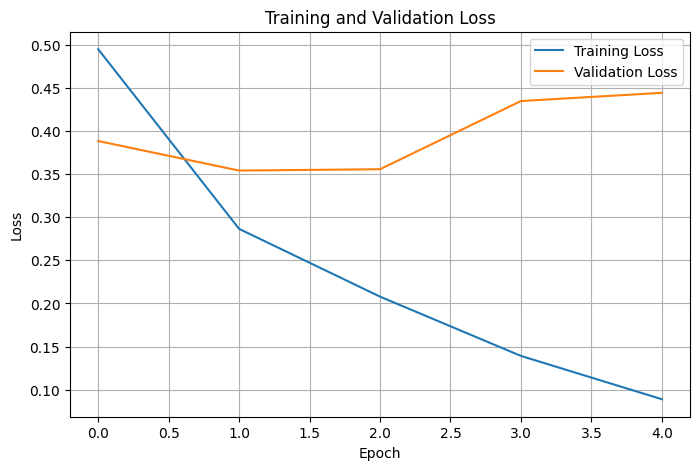

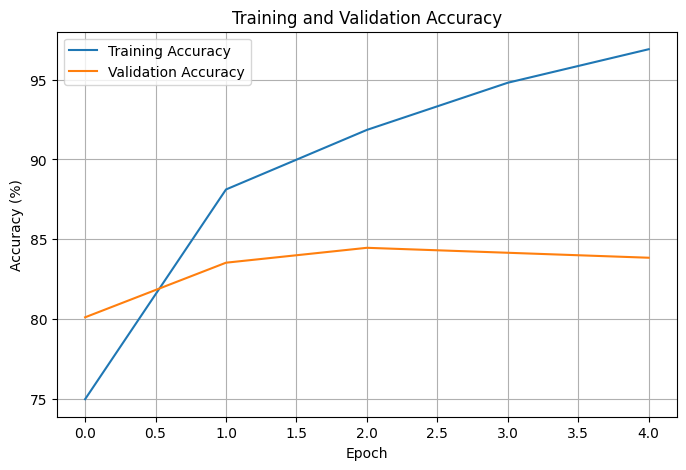

In [40]:
import matplotlib.pyplot as plt

# Training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()